<a href="https://colab.research.google.com/github/elias8080007/Fashion-MNIST-Clothing-Classifier/blob/main/Fashion_MNIST_Clothing_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clothing Image Classification: NN, CNN and Transfer Learning

## Project Objective

This project develops an image-classification system that predicts the
category of a clothing item using the Fashion-MNIST dataset.

Three deep-learning approaches will be implemented and compared:

1. Baseline fully connected neural network
2. Convolutional Neural Network (CNN)
3. MobileNet transfer learning and fine-tuning

The models will be evaluated using accuracy, loss, precision, recall,
F1-score and confusion matrices.

## Dataset

Fashion-MNIST contains 70,000 grayscale clothing images belonging to
10 categories:

- 60,000 training images
- 10,000 testing images
- Image dimensions: 28 × 28 pixels
- Number of classes: 10

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Make the results more reproducible
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(X_train_full, y_train_full), (X_test, y_test) = (
    keras.datasets.fashion_mnist.load_data()
)

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Dataset loaded successfully.")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully.


In [3]:
print("X_train_full shape:", X_train_full.shape)
print("y_train_full shape:", y_train_full.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nNumber of training images:", len(X_train_full))
print("Number of testing images:", len(X_test))
print("Image dimensions:", X_train_full[0].shape)
print("Number of classes:", len(class_names))

X_train_full shape: (60000, 28, 28)
y_train_full shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)

Number of training images: 60000
Number of testing images: 10000
Image dimensions: (28, 28)
Number of classes: 10


In [4]:
sample_index = 0

print("Numerical label:", y_train_full[sample_index])
print("Class name:", class_names[y_train_full[sample_index]])
print("Image shape:", X_train_full[sample_index].shape)
print("Minimum pixel value:", X_train_full[sample_index].min())
print("Maximum pixel value:", X_train_full[sample_index].max())

Numerical label: 9
Class name: Ankle boot
Image shape: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255


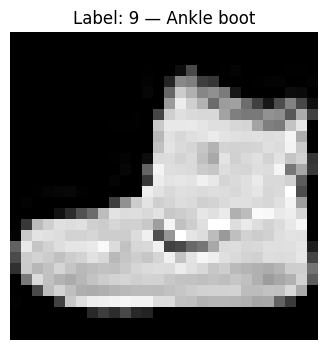

In [5]:
plt.figure(figsize=(4, 4))

plt.imshow(X_train_full[sample_index], cmap="gray")
plt.title(
    f"Label: {y_train_full[sample_index]} — "
    f"{class_names[y_train_full[sample_index]]}"
)
plt.axis("off")
plt.show()

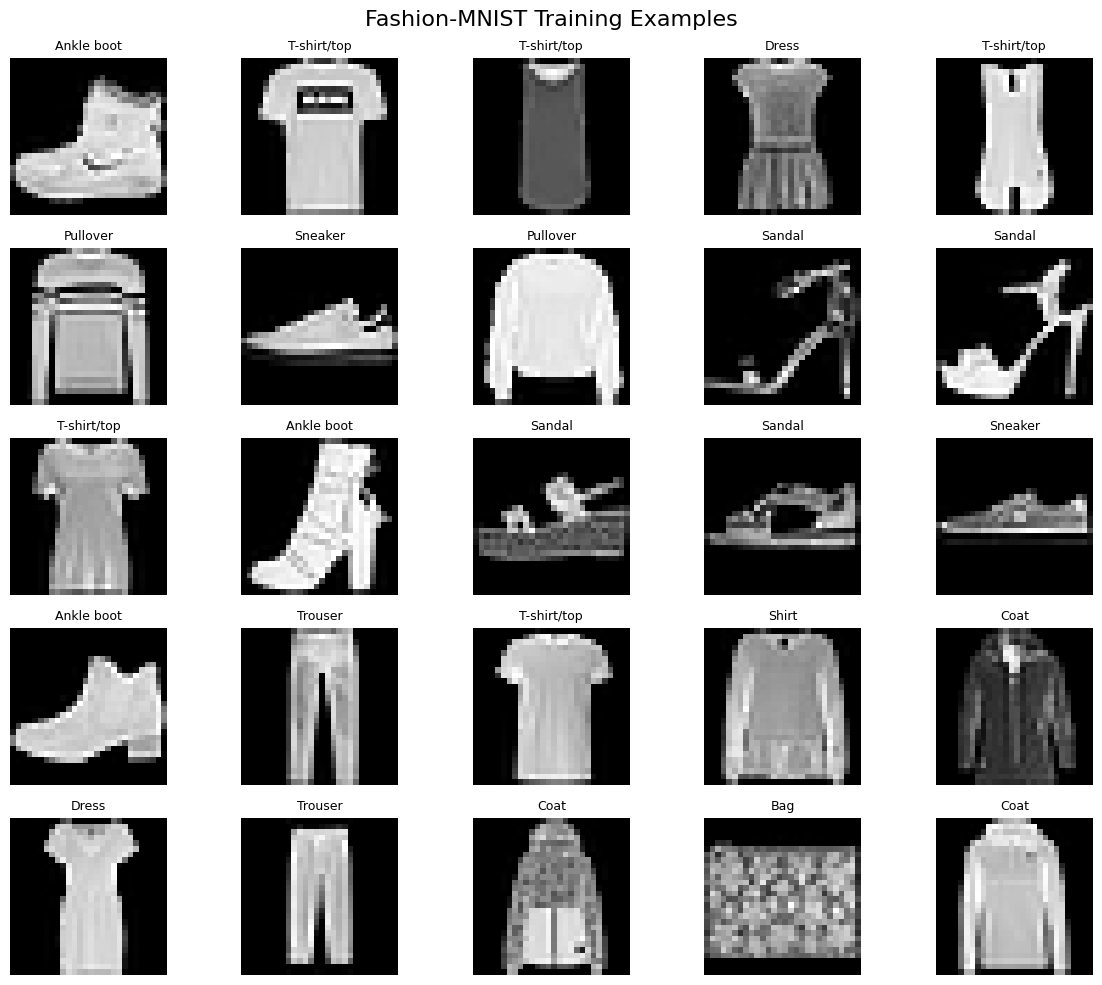

In [6]:
plt.figure(figsize=(12, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]], fontsize=9)
    plt.axis("off")

plt.suptitle("Fashion-MNIST Training Examples", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Class ID": range(10),
    "Class Name": class_names,
    "Training Images": train_counts.values,
    "Testing Images": test_counts.values
})

distribution_df

,Class ID,Class Name,Training Images,Testing Images
0,0,T-shirt/top,6000,1000
1,1,Trouser,6000,1000
2,2,Pullover,6000,1000
3,3,Dress,6000,1000
4,4,Coat,6000,1000
5,5,Sandal,6000,1000
6,6,Shirt,6000,1000
7,7,Sneaker,6000,1000
8,8,Bag,6000,1000
9,9,Ankle boot,6000,1000


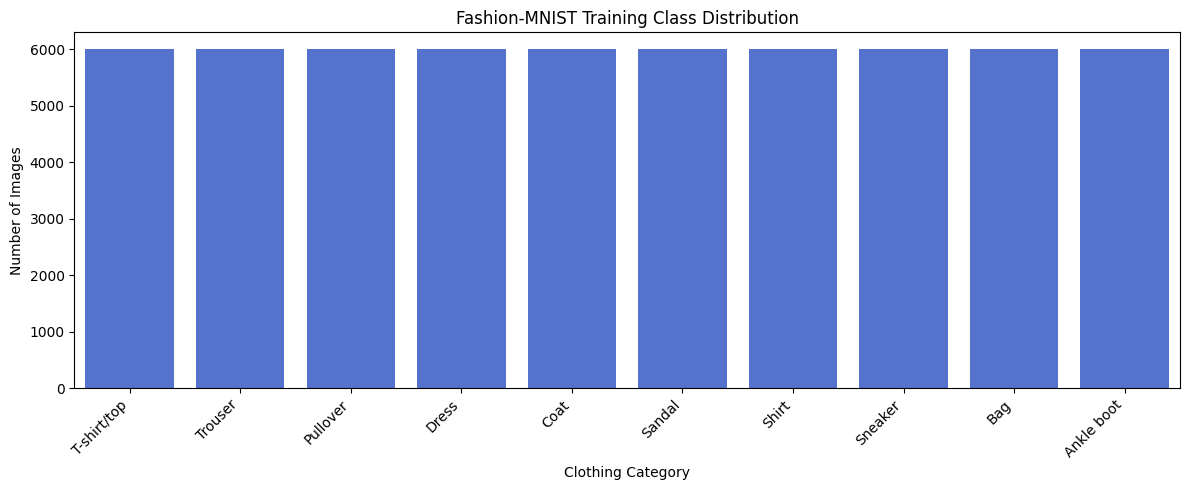

In [8]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=distribution_df,
    x="Class Name",
    y="Training Images",
    color="royalblue"
)

plt.title("Fashion-MNIST Training Class Distribution")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

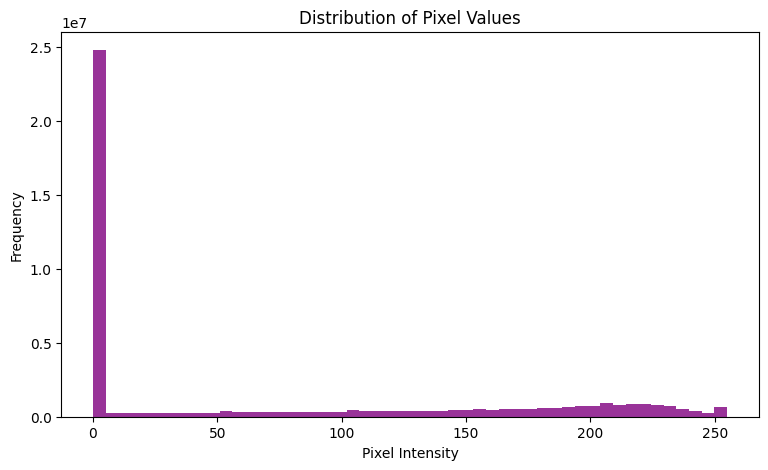

In [9]:
plt.figure(figsize=(9, 5))

plt.hist(
    X_train_full.reshape(-1),
    bins=50,
    color="purple",
    alpha=0.8
)

plt.title("Distribution of Pixel Values")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

In [10]:
print("Missing values in training images:", np.isnan(X_train_full).sum())
print("Missing values in testing images:", np.isnan(X_test).sum())

print("\nTraining pixel range:",
      X_train_full.min(), "to", X_train_full.max())

print("Testing pixel range:",
      X_test.min(), "to", X_test.max())

print("\nTraining labels:", np.unique(y_train_full))
print("Testing labels:", np.unique(y_test))

Missing values in training images: 0
Missing values in testing images: 0

Training pixel range: 0 to 255
Testing pixel range: 0 to 255

Training labels: [0 1 2 3 4 5 6 7 8 9]
Testing labels: [0 1 2 3 4 5 6 7 8 9]


In [11]:
X_train = X_train_full[:50000]
y_train = y_train_full[:50000]

X_val = X_train_full[50000:]
y_val = y_train_full[50000:]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation images:", X_val.shape)
print("Validation labels:", y_val.shape)

print("\nTesting images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 28, 28)
Training labels: (50000,)

Validation images: (10000, 28, 28)
Validation labels: (10000,)

Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [12]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test_normalized = X_test.astype("float32") / 255.0

print("Before normalization:")
print("Minimum:", X_train_full.min())
print("Maximum:", X_train_full.max())

print("\nAfter normalization:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Before normalization:
Minimum: 0
Maximum: 255

After normalization:
Minimum: 0.0
Maximum: 1.0


Training distribution:


,Class,Count
0,T-shirt/top,4977
1,Trouser,5012
2,Pullover,4992
3,Dress,4979
4,Coat,4950
5,Sandal,5004
6,Shirt,5030
7,Sneaker,5045
8,Bag,5032
9,Ankle boot,4979


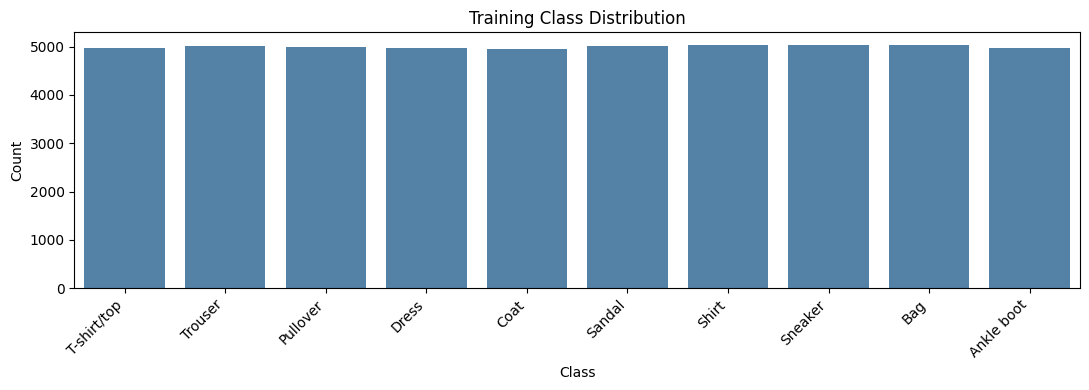

Validation distribution:


,Class,Count
0,T-shirt/top,1023
1,Trouser,988
2,Pullover,1008
3,Dress,1021
4,Coat,1050
5,Sandal,996
6,Shirt,970
7,Sneaker,955
8,Bag,968
9,Ankle boot,1021


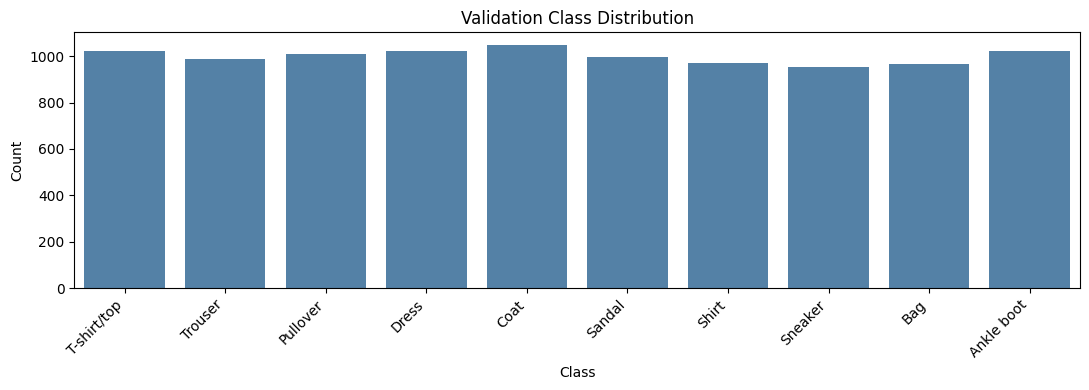

In [13]:
def display_class_distribution(labels, dataset_name):
    counts = np.bincount(labels, minlength=10)

    distribution = pd.DataFrame({
        "Class": class_names,
        "Count": counts
    })

    print(f"{dataset_name} distribution:")
    display(distribution)

    plt.figure(figsize=(11, 4))
    sns.barplot(
        data=distribution,
        x="Class",
        y="Count",
        color="steelblue"
    )
    plt.title(f"{dataset_name} Class Distribution")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


display_class_distribution(y_train, "Training")
display_class_distribution(y_val, "Validation")

## Baseline Fully Connected Neural Network

The baseline model converts each 28 × 28 image into a vector containing
784 pixel values. These values are processed by fully connected dense
layers before the model produces probabilities for the 10 clothing
categories.

This model provides a reference point for evaluating the CNN and
transfer-learning models.

In [14]:
baseline_model = keras.Sequential([
    layers.Input(shape=(28, 28)),

    # Convert the 28 × 28 image into 784 values
    layers.Flatten(),

    # Learn combinations of the pixel values
    layers.Dense(128, activation="relu"),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Produce probabilities for the 10 categories
    layers.Dense(10, activation="softmax")
], name="baseline_nn")

baseline_model.summary()

Model: "baseline_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_learning_rate = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [17]:
baseline_history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping, reduce_learning_rate],
    verbose=1
)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7782 - loss: 0.6421 - val_accuracy: 0.8349 - val_loss: 0.4666 - learning_rate: 0.0010
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8427 - loss: 0.4466 - val_accuracy: 0.8545 - val_loss: 0.4170 - learning_rate: 0.0010
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8550 - loss: 0.4061 - val_accuracy: 0.8645 - val_loss: 0.3809 - learning_rate: 0.0010
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8638 - loss: 0.3773 - val_accuracy: 0.8705 - val_loss: 0.3646 - learning_rate: 0.0010
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8699 - loss: 0.3608 - val_accuracy: 0.8706 - val_loss: 0.3684 - learning_rate: 0.0010
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8747 - loss: 0.3443 - val_accuracy: 0.8751 - val_loss: 0.3490 - learning_rate: 0.0010
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8782 - loss: 0.3358 -

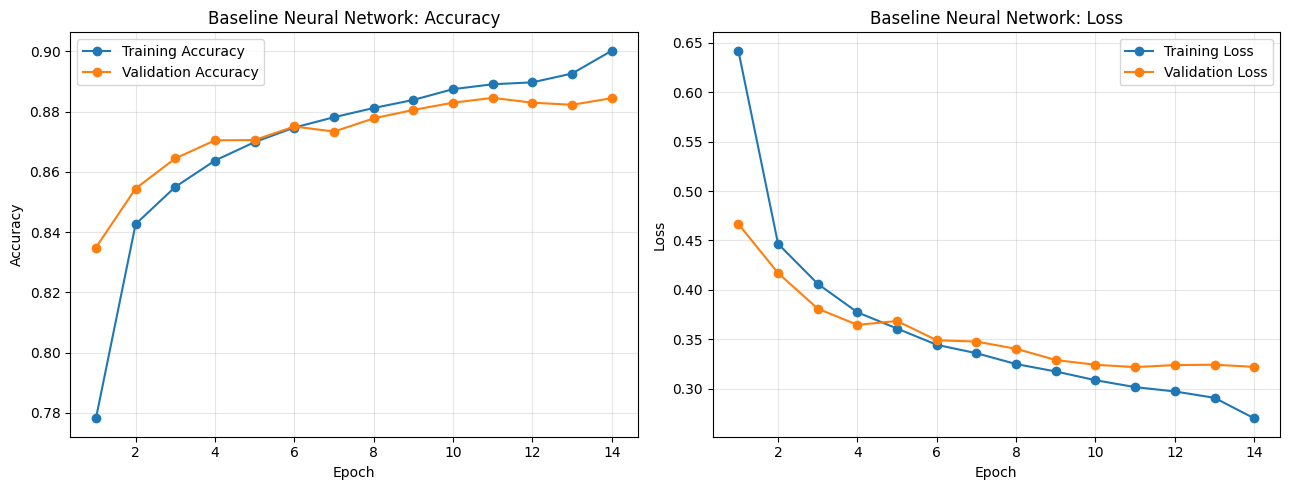

In [18]:
def plot_training_history(history, model_name):
    history_data = history.history
    epochs_range = range(1, len(history_data["loss"]) + 1)

    plt.figure(figsize=(13, 5))

    # Accuracy graph
    plt.subplot(1, 2, 1)
    plt.plot(
        epochs_range,
        history_data["accuracy"],
        marker="o",
        label="Training Accuracy"
    )
    plt.plot(
        epochs_range,
        history_data["val_accuracy"],
        marker="o",
        label="Validation Accuracy"
    )
    plt.title(f"{model_name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    # Loss graph
    plt.subplot(1, 2, 2)
    plt.plot(
        epochs_range,
        history_data["loss"],
        marker="o",
        label="Training Loss"
    )
    plt.plot(
        epochs_range,
        history_data["val_loss"],
        marker="o",
        label="Validation Loss"
    )
    plt.title(f"{model_name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_training_history(
    baseline_history,
    "Baseline Neural Network"
)

In [19]:
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    X_test_normalized,
    y_test,
    verbose=0
)

print(f"Baseline test loss: {baseline_test_loss:.4f}")
print(f"Baseline test accuracy: {baseline_test_accuracy:.4f}")
print(f"Baseline test accuracy: {baseline_test_accuracy * 100:.2f}%")

Baseline test loss: 0.3479
Baseline test accuracy: 0.8766
Baseline test accuracy: 87.66%


In [20]:
baseline_probabilities = baseline_model.predict(
    X_test_normalized,
    verbose=0
)

baseline_predictions = np.argmax(
    baseline_probabilities,
    axis=1
)

print("Probability array shape:", baseline_probabilities.shape)
print("Predicted labels shape:", baseline_predictions.shape)

print("\nFirst 10 actual labels:")
print(y_test[:10])

print("\nFirst 10 predicted labels:")
print(baseline_predictions[:10])

Probability array shape: (10000, 10)
Predicted labels shape: (10000,)

First 10 actual labels:
[9 2 1 1 6 1 4 6 5 7]

First 10 predicted labels:
[9 2 1 1 6 1 4 6 5 7]


In [21]:
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

 T-shirt/top     0.8255    0.8420    0.8337      1000
     Trouser     0.9868    0.9690    0.9778      1000
    Pullover     0.8058    0.7550    0.7796      1000
       Dress     0.8728    0.8990    0.8857      1000
        Coat     0.8068    0.7640    0.7848      1000
      Sandal     0.9686    0.9570    0.9628      1000
       Shirt     0.6632    0.7050    0.6835      1000
     Sneaker     0.9186    0.9700    0.9436      1000
         Bag     0.9520    0.9710    0.9614      1000
  Ankle boot     0.9760    0.9340    0.9545      1000

    accuracy                         0.8766     10000
   macro avg     0.8776    0.8766    0.8767     10000
weighted avg     0.8776    0.8766    0.8767     10000



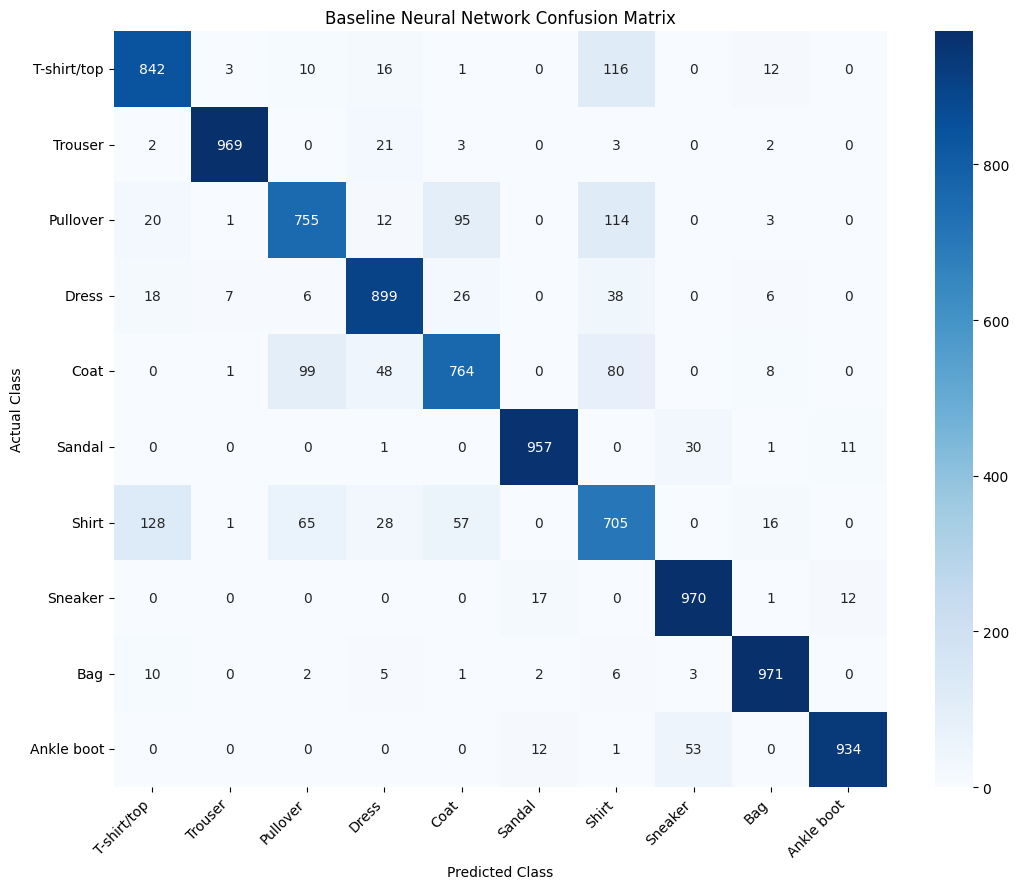

In [22]:
baseline_cm = confusion_matrix(
    y_test,
    baseline_predictions
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Baseline Neural Network Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

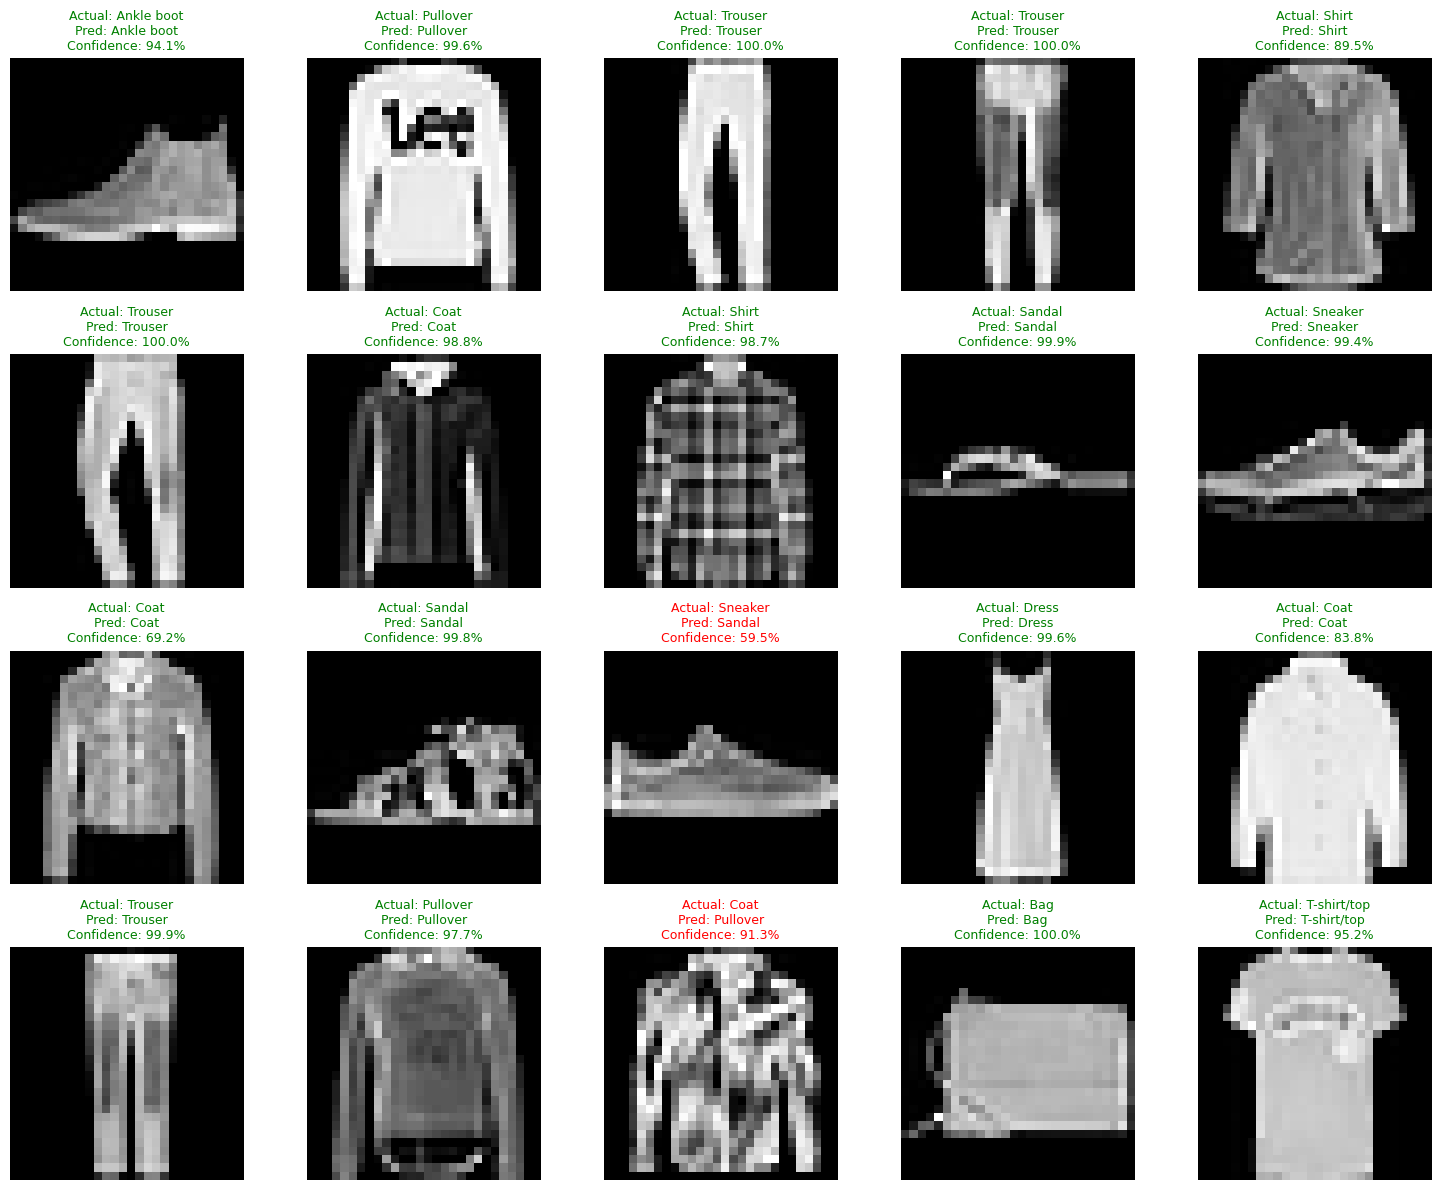

In [23]:
def show_predictions(
    images,
    actual_labels,
    predicted_labels,
    probabilities,
    class_names,
    number_of_images=20
):
    plt.figure(figsize=(15, 12))

    for i in range(number_of_images):
        plt.subplot(4, 5, i + 1)
        plt.imshow(images[i], cmap="gray")

        actual_name = class_names[actual_labels[i]]
        predicted_name = class_names[predicted_labels[i]]
        confidence = probabilities[i][predicted_labels[i]] * 100

        title_color = (
            "green"
            if predicted_labels[i] == actual_labels[i]
            else "red"
        )

        plt.title(
            f"Actual: {actual_name}\n"
            f"Pred: {predicted_name}\n"
            f"Confidence: {confidence:.1f}%",
            color=title_color,
            fontsize=9
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(
    X_test,
    y_test,
    baseline_predictions,
    baseline_probabilities,
    class_names
)

In [24]:
model_results = []

model_results.append({
    "Model": "Baseline Neural Network",
    "Test Loss": baseline_test_loss,
    "Test Accuracy": baseline_test_accuracy
})

results_df = pd.DataFrame(model_results)
results_df

,Model,Test Loss,Test Accuracy
0,Baseline Neural Network,0.347914,0.8766


In [25]:
X_train_cnn = np.expand_dims(X_train, axis=-1)
X_val_cnn = np.expand_dims(X_val, axis=-1)
X_test_cnn = np.expand_dims(X_test_normalized, axis=-1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN validation shape:", X_val_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)

CNN training shape: (50000, 28, 28, 1)
CNN validation shape: (10000, 28, 28, 1)
CNN testing shape: (10000, 28, 28, 1)


## Convolutional Neural Network

Unlike the baseline neural network, the CNN preserves the spatial
structure of each image.

Convolutional layers extract features such as edges, curves and clothing
shapes. Max-pooling layers reduce the dimensions of the feature maps,
while batch normalization and dropout improve training stability and
reduce overfitting.

In [26]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # First convolutional block
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),

    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Second convolutional block
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Classification block
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # Output probabilities
    layers.Dense(10, activation="softmax")
], name="fashion_mnist_cnn")

cnn_model.summary()

Model: "fashion_mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,202 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 192 (768.00 B)

In [27]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [28]:
cnn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

cnn_reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [29]:
cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[
        cnn_early_stopping,
        cnn_reduce_lr
    ],
    verbose=1
)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.7685 - loss: 0.6472 - val_accuracy: 0.7029 - val_loss: 0.8377 - learning_rate: 0.0010
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8569 - loss: 0.3980 - val_accuracy: 0.8990 - val_loss: 0.2925 - learning_rate: 0.0010
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8817 - loss: 0.3343 - val_accuracy: 0.9047 - val_loss: 0.2649 - learning_rate: 0.0010
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8923 - loss: 0.3042 - val_accuracy: 0.8961 - val_loss: 0.2705 - learning_rate: 0.0010
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9006 - loss: 0.2783 - val_accuracy: 0.9165 - val_loss: 0.2319 - learning_rate: 0.0010
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9048 - loss: 0.2634 - val_accuracy: 0.9139 - val_loss: 0.2460 - learning_rate: 0.0010
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9095 - loss: 0.24

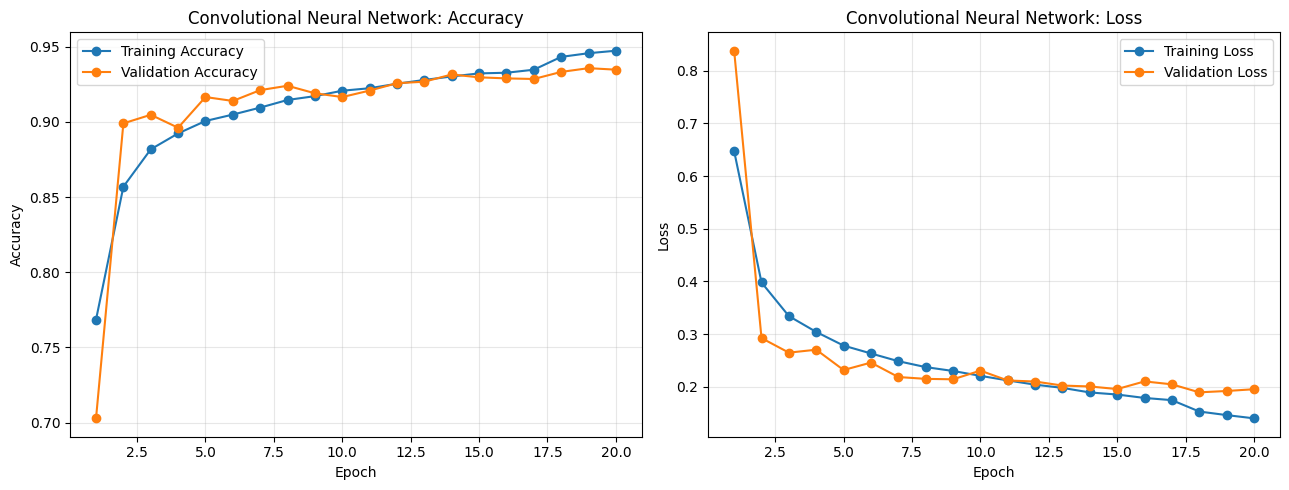

In [30]:
plot_training_history(
    cnn_history,
    "Convolutional Neural Network"
)

In [31]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy * 100:.2f}%")

CNN test loss: 0.2173
CNN test accuracy: 0.9314
CNN test accuracy: 93.14%


In [32]:
cnn_probabilities = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_predictions = np.argmax(
    cnn_probabilities,
    axis=1
)

print("Probability array shape:", cnn_probabilities.shape)
print("Predicted labels shape:", cnn_predictions.shape)

print("\nFirst 10 actual labels:")
print(y_test[:10])

print("\nFirst 10 CNN predictions:")
print(cnn_predictions[:10])

Probability array shape: (10000, 10)
Predicted labels shape: (10000,)

First 10 actual labels:
[9 2 1 1 6 1 4 6 5 7]

First 10 CNN predictions:
[9 2 1 1 6 1 4 6 5 7]


In [33]:
print("CNN Classification Report:\n")

print(
    classification_report(
        y_test,
        cnn_predictions,
        target_names=class_names,
        digits=4
    )
)

CNN Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8899    0.8730    0.8814      1000
     Trouser     0.9970    0.9910    0.9940      1000
    Pullover     0.9434    0.8670    0.9036      1000
       Dress     0.9313    0.9360    0.9337      1000
        Coat     0.8563    0.9240    0.8889      1000
      Sandal     0.9939    0.9830    0.9884      1000
       Shirt     0.7849    0.7990    0.7919      1000
     Sneaker     0.9572    0.9850    0.9709      1000
         Bag     0.9880    0.9900    0.9890      1000
  Ankle boot     0.9817    0.9660    0.9738      1000

    accuracy                         0.9314     10000
   macro avg     0.9324    0.9314    0.9316     10000
weighted avg     0.9324    0.9314    0.9316     10000



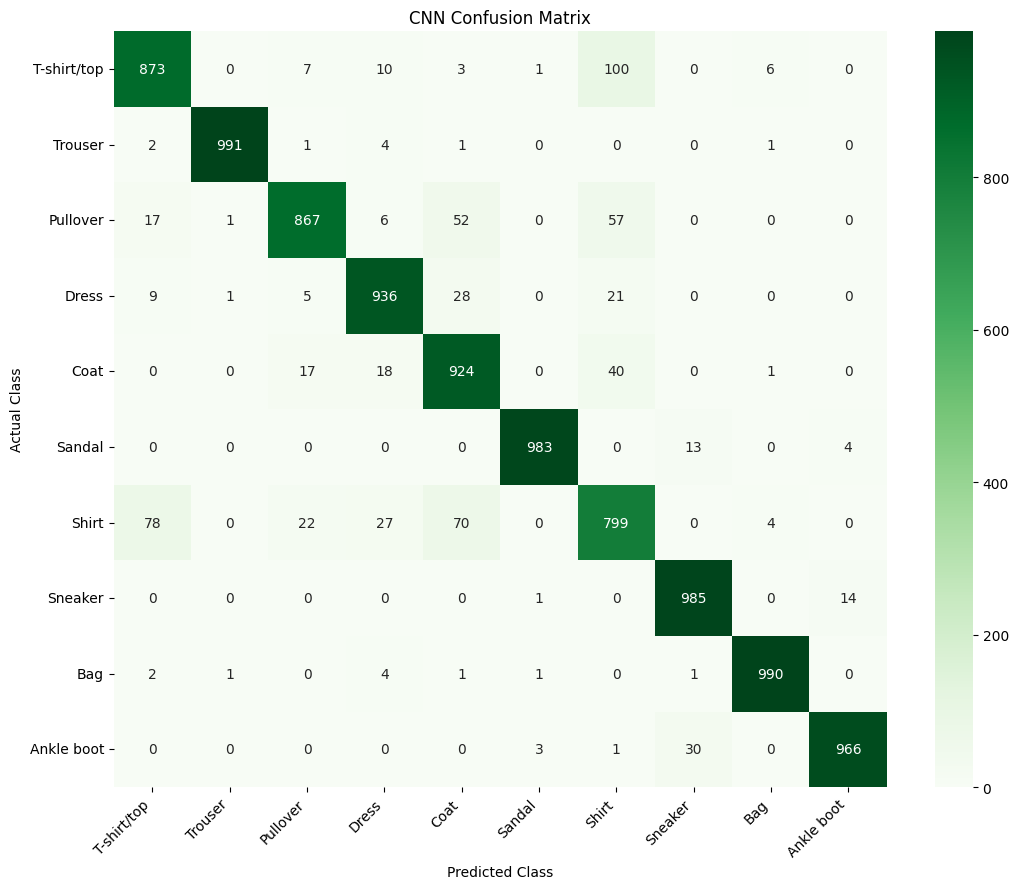

In [34]:
cnn_cm = confusion_matrix(
    y_test,
    cnn_predictions
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

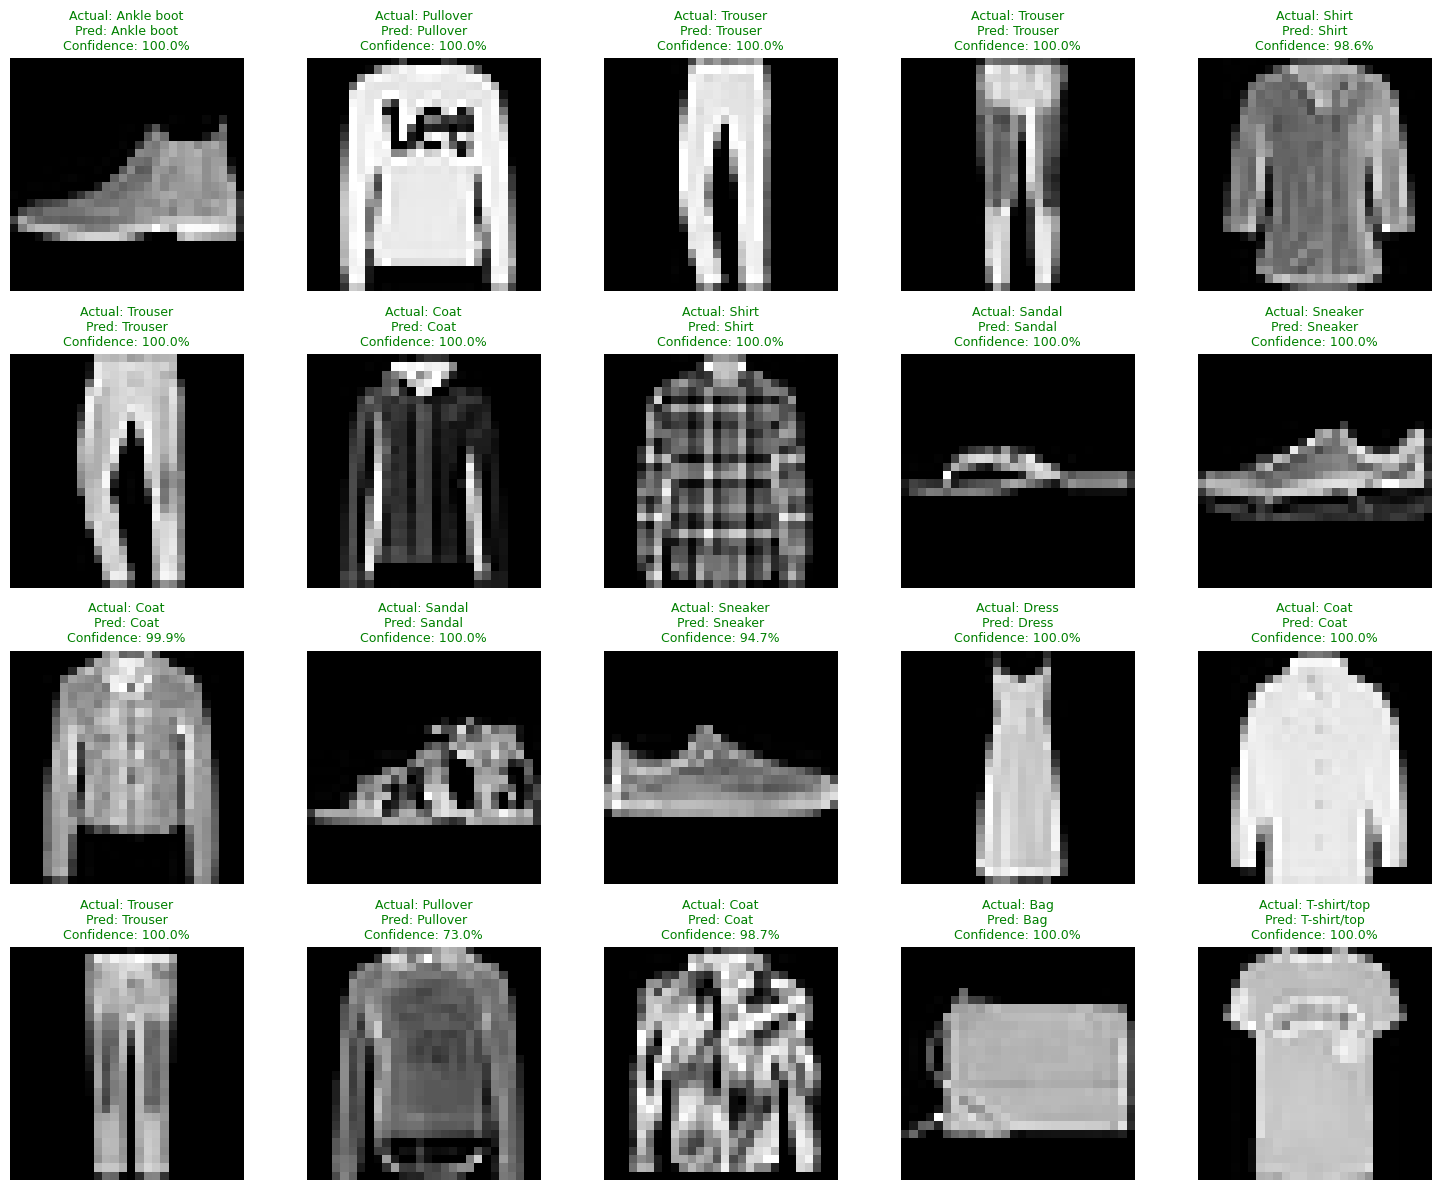

In [35]:
show_predictions(
    X_test,
    y_test,
    cnn_predictions,
    cnn_probabilities,
    class_names
)

Number of incorrect CNN predictions: 686


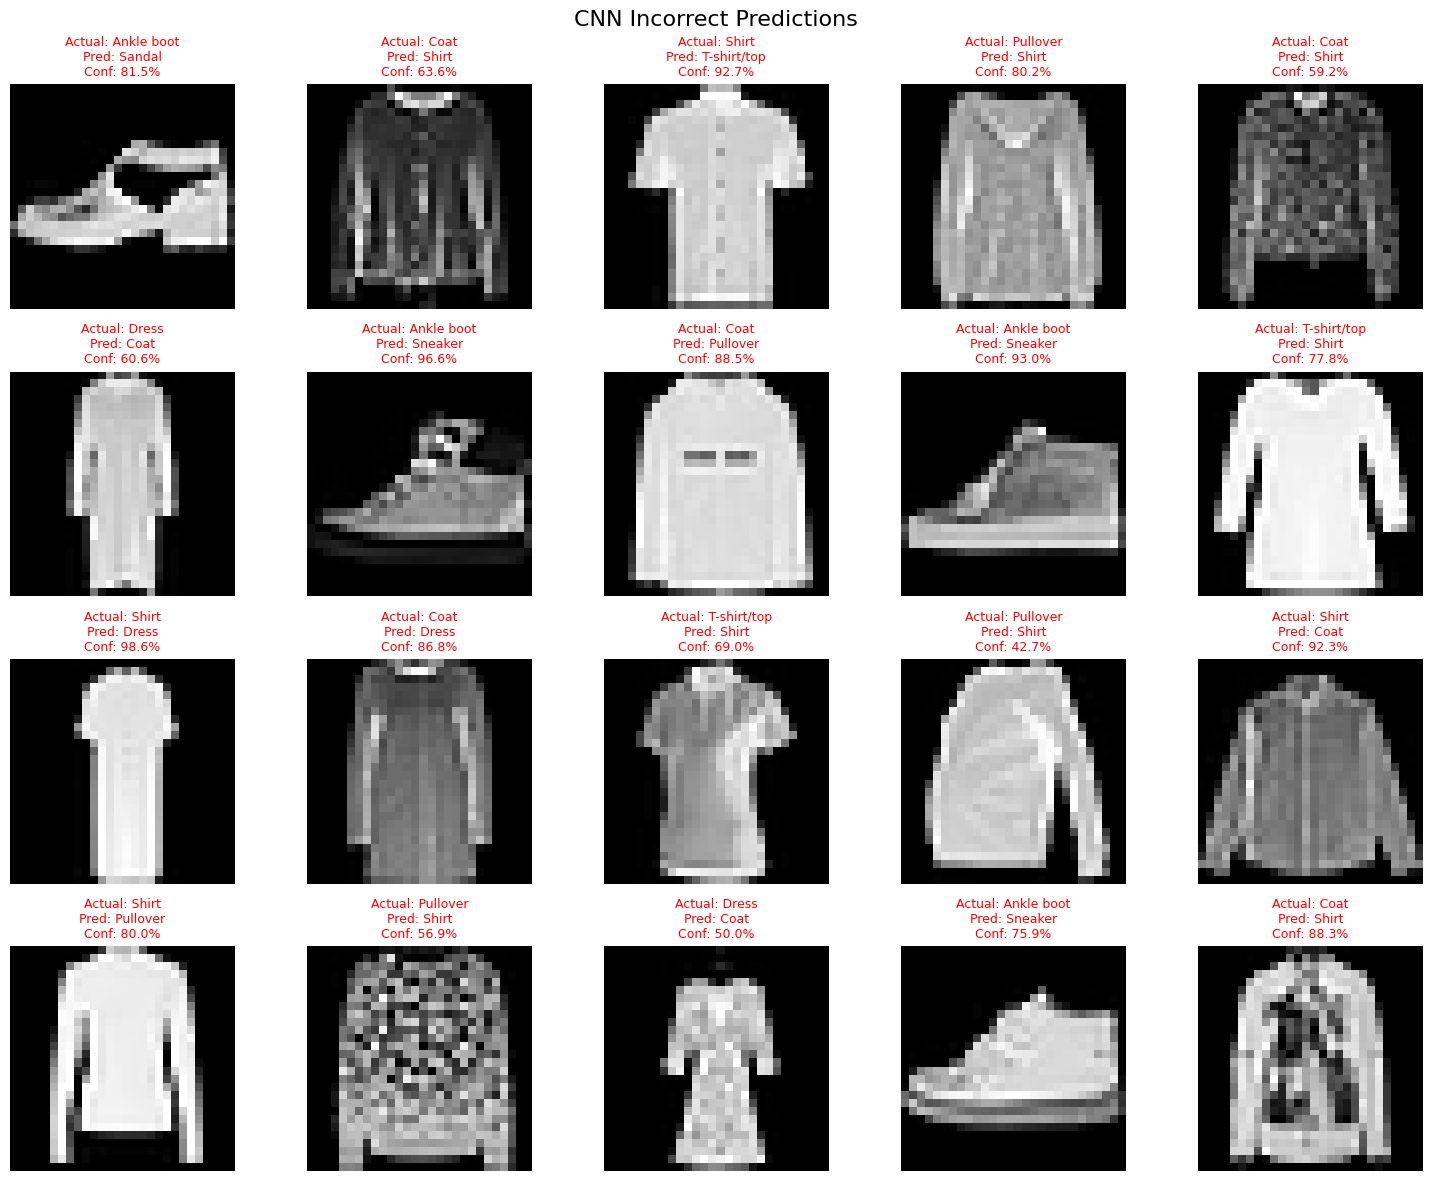

In [36]:
incorrect_indices = np.where(
    cnn_predictions != y_test
)[0]

print("Number of incorrect CNN predictions:",
      len(incorrect_indices))

plt.figure(figsize=(15, 12))

for plot_position, image_index in enumerate(
    incorrect_indices[:20]
):
    plt.subplot(4, 5, plot_position + 1)

    plt.imshow(X_test[image_index], cmap="gray")

    actual_name = class_names[y_test[image_index]]
    predicted_name = class_names[cnn_predictions[image_index]]
    confidence = (
        cnn_probabilities[image_index][
            cnn_predictions[image_index]
        ] * 100
    )

    plt.title(
        f"Actual: {actual_name}\n"
        f"Pred: {predicted_name}\n"
        f"Conf: {confidence:.1f}%",
        color="red",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("CNN Incorrect Predictions", fontsize=16)
plt.tight_layout()
plt.show()

In [37]:
model_results.append({
    "Model": "Convolutional Neural Network",
    "Test Loss": cnn_test_loss,
    "Test Accuracy": cnn_test_accuracy
})

results_df = pd.DataFrame(model_results)
results_df

,Model,Test Loss,Test Accuracy
0,Baseline Neural Network,0.347914,0.8766
1,Convolutional Neural Network,0.217312,0.9314


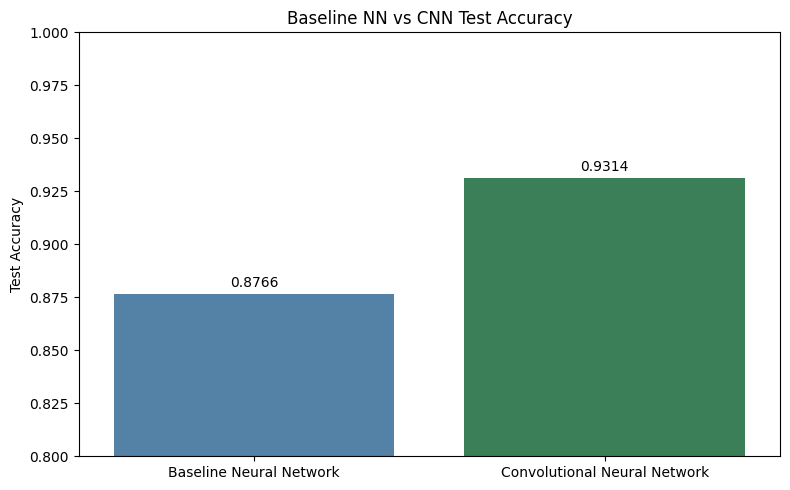

In [38]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Test Accuracy",
    hue="Model",
    palette=["steelblue", "seagreen"],
    legend=False
)

plt.title("Baseline NN vs CNN Test Accuracy")
plt.xlabel("")
plt.ylabel("Test Accuracy")
plt.ylim(0.80, 1.00)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()
plt.show()

### CNN Result Interpretation

The CNN achieved a test accuracy of 93.14%, compared with 87.66% for
the baseline neural network. This represents an improvement of 5.48
percentage points and approximately a 44.4% reduction in classification
error.

The CNN also reduced test loss from 0.3479 to 0.2173. This improvement
occurred because convolutional layers preserve spatial relationships
between pixels and learn relevant visual features such as edges, shapes
and clothing patterns. The baseline model flattened the images and
could not exploit these spatial relationships as effectively.

In [39]:
MOBILENET_SIZE = 96
MOBILENET_BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_cnn, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(
        buffer_size=10000,
        seed=SEED,
        reshuffle_each_iteration=True
    )
    .batch(MOBILENET_BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset
    .from_tensor_slices((X_val_cnn, y_val))
    .batch(MOBILENET_BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset
    .from_tensor_slices((X_test_cnn, y_test))
    .batch(MOBILENET_BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Transfer-learning datasets created.")

Transfer-learning datasets created.


In [40]:
mobilenet_base = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(
        MOBILENET_SIZE,
        MOBILENET_SIZE,
        3
    )
)

mobilenet_base.trainable = False

print("MobileNetV2 loaded.")
print("Base model trainable:", mobilenet_base.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded.
Base model trainable: False


In [43]:
# Input: Fashion-MNIST grayscale image
mobilenet_inputs = keras.Input(
    shape=(28, 28, 1),
    name="fashion_image"
)

# Resize from 28×28 to 96×96
x = layers.Resizing(
    MOBILENET_SIZE,
    MOBILENET_SIZE,
    name="resize"
)(mobilenet_inputs)

# Convert 1 grayscale channel to 3 identical channels
x = layers.Concatenate(
    axis=-1,
    name="grayscale_to_rgb"
)([x, x, x])

# Convert pixel range from 0–1 to -1–1
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0,
    name="mobilenet_preprocessing"
)(x)

# Extract pretrained features
x = mobilenet_base(
    x,
    training=False
)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    0.3,
    name="transfer_dropout"
)(x)

# Predict one of the 10 clothing classes
mobilenet_outputs = layers.Dense(
    10,
    activation="softmax",
    name="clothing_classifier"
)(x)

# Create final model
mobilenet_model = keras.Model(
    inputs=mobilenet_inputs,
    outputs=mobilenet_outputs,
    name="fashion_mobilenet_v2"
)

mobilenet_model.summary()

Model: "fashion_mobilenet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ fashion_image       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resize (Resizing)   │ (None, 96, 96, 1) │          0 │ fashion_image[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ grayscale_to_rgb    │ (None, 96, 96, 3) │          0 │ resize[0][0],     │
│ (Concatenate)       │                   │            │ resize[0][0],     │
│                     │                   │            │ resize[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_preproce… │ (None, 96, 96, 3) │          0 │ grayscale_to_rgb… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_96 │ (None, 3, 3,      │  2,257,984 │ mobilenet_prepro… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transfer_dropout    │ (None, 1280)      │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clothing_classifier │ (None, 10)        │     12,810 │ transfer_dropout… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [44]:
sample_batch = X_train_cnn[:2]

sample_predictions = mobilenet_model(sample_batch)

print("Input shape:", sample_batch.shape)
print("Output shape:", sample_predictions.shape)

Input shape: (2, 28, 28, 1)
Output shape: (2, 10)


In [45]:
print("MobileNet base trainable:", mobilenet_base.trainable)

trainable_parameters = np.sum([
    np.prod(variable.shape)
    for variable in mobilenet_model.trainable_weights
])

non_trainable_parameters = np.sum([
    np.prod(variable.shape)
    for variable in mobilenet_model.non_trainable_weights
])

print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Non-trainable parameters: {non_trainable_parameters:,}")

MobileNet base trainable: False
Trainable parameters: 12,810
Non-trainable parameters: 2,257,984


In [46]:
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [47]:
mobilenet_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

mobilenet_reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [48]:
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=[
        mobilenet_early_stopping,
        mobilenet_reduce_lr
    ],
    verbose=1
)

Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.8034 - loss: 0.5603 - val_accuracy: 0.8729 - val_loss: 0.3497 - learning_rate: 0.0010
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.8676 - loss: 0.3645 - val_accuracy: 0.8833 - val_loss: 0.3190 - learning_rate: 0.0010
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8780 - loss: 0.3363 - val_accuracy: 0.8933 - val_loss: 0.3002 - learning_rate: 0.0010
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8821 - loss: 0.3220 - val_accuracy: 0.8951 - val_loss: 0.2955 - learning_rate: 0.0010
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8851 - loss: 0.3130 - val_accuracy: 0.8986 - val_loss: 0.2906 - learning_rate: 0.0010
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.8876 - loss: 0.3081 - val_accuracy: 0.8917 - val_loss: 0.2983 - learning_rate: 0.0010
Epoch 7/15
389/391 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8858 - loss: 0

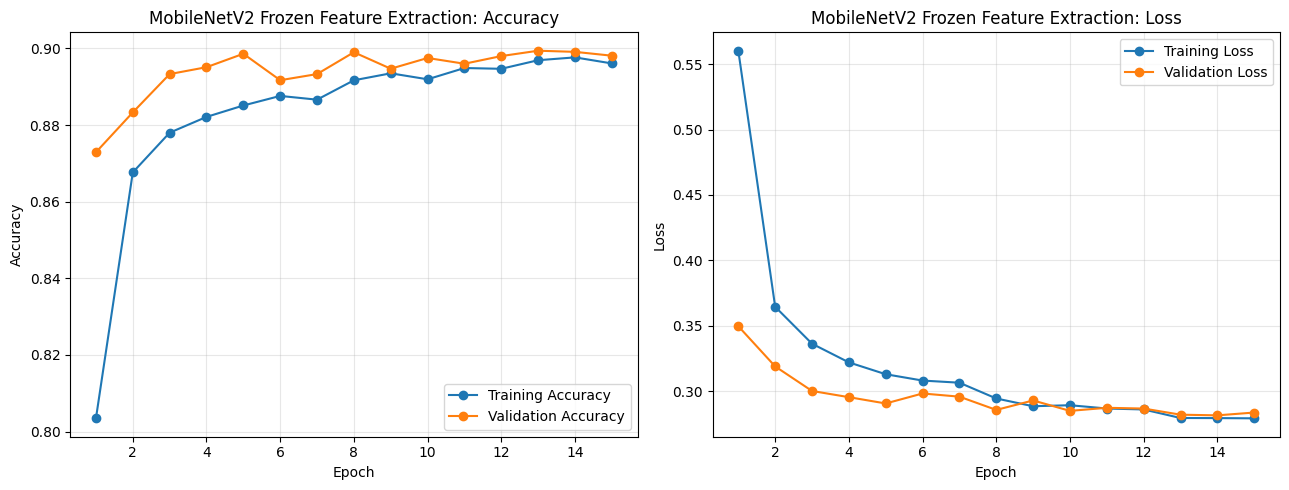

In [49]:
plot_training_history(
    mobilenet_history,
    "MobileNetV2 Frozen Feature Extraction"
)

In [50]:
mobilenet_frozen_loss, mobilenet_frozen_accuracy = (
    mobilenet_model.evaluate(
        test_dataset,
        verbose=0
    )
)

print(
    f"Frozen MobileNet test loss: "
    f"{mobilenet_frozen_loss:.4f}"
)

print(
    f"Frozen MobileNet test accuracy: "
    f"{mobilenet_frozen_accuracy:.4f}"
)

print(
    f"Frozen MobileNet test accuracy: "
    f"{mobilenet_frozen_accuracy * 100:.2f}%"
)

Frozen MobileNet test loss: 0.2979
Frozen MobileNet test accuracy: 0.8923
Frozen MobileNet test accuracy: 89.23%


In [51]:
mobilenet_frozen_probabilities = mobilenet_model.predict(
    test_dataset,
    verbose=1
)

mobilenet_frozen_predictions = np.argmax(
    mobilenet_frozen_probabilities,
    axis=1
)

print(
    "Probability array shape:",
    mobilenet_frozen_probabilities.shape
)

print(
    "Prediction array shape:",
    mobilenet_frozen_predictions.shape
)

print("\nFirst 10 actual labels:")
print(y_test[:10])

print("\nFirst 10 predictions:")
print(mobilenet_frozen_predictions[:10])

79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 66ms/step
Probability array shape: (10000, 10)
Prediction array shape: (10000,)

First 10 actual labels:
[9 2 1 1 6 1 4 6 5 7]

First 10 predictions:
[9 2 1 1 6 1 4 6 5 7]


In [52]:
print("Frozen MobileNet Classification Report:\n")

print(
    classification_report(
        y_test,
        mobilenet_frozen_predictions,
        target_names=class_names,
        digits=4
    )
)

Frozen MobileNet Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8623    0.8390    0.8505      1000
     Trouser     0.9919    0.9760    0.9839      1000
    Pullover     0.8324    0.8490    0.8406      1000
       Dress     0.8794    0.8750    0.8772      1000
        Coat     0.8078    0.8320    0.8197      1000
      Sandal     0.9786    0.9610    0.9697      1000
       Shirt     0.6885    0.6830    0.6857      1000
     Sneaker     0.9299    0.9690    0.9491      1000
         Bag     0.9830    0.9850    0.9840      1000
  Ankle boot     0.9735    0.9540    0.9636      1000

    accuracy                         0.8923     10000
   macro avg     0.8927    0.8923    0.8924     10000
weighted avg     0.8927    0.8923    0.8924     10000



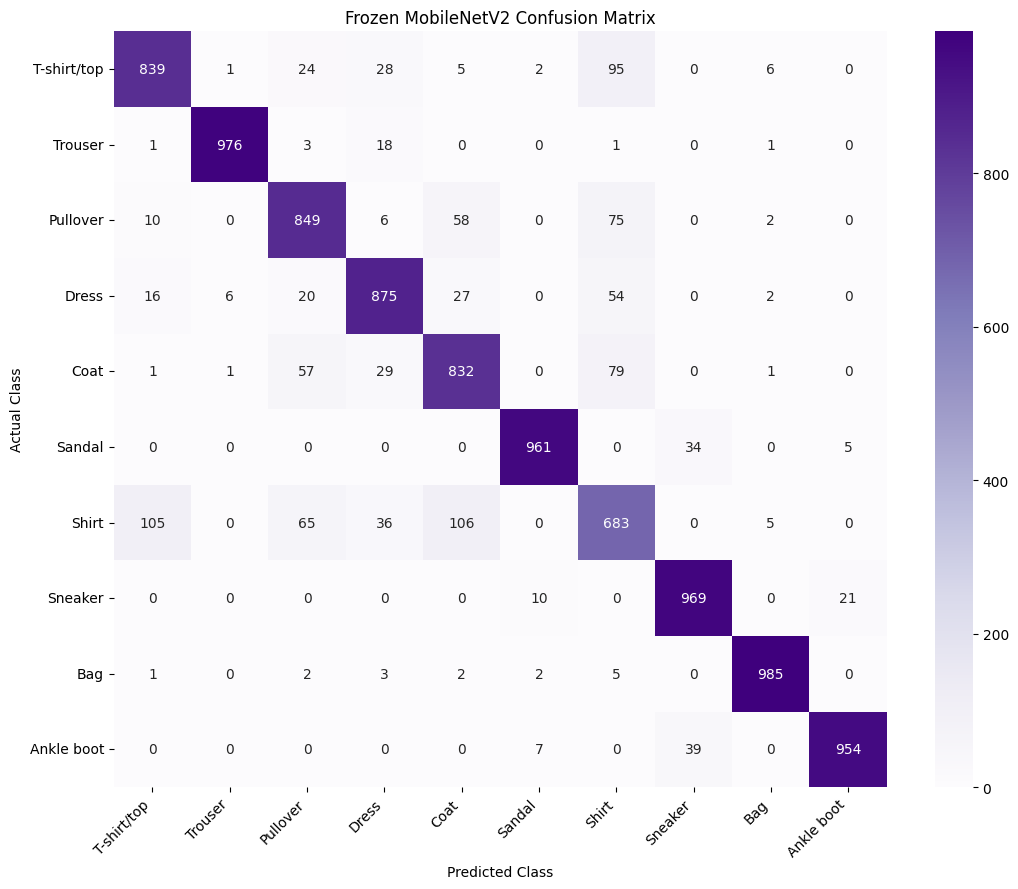

In [53]:
mobilenet_frozen_cm = confusion_matrix(
    y_test,
    mobilenet_frozen_predictions
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    mobilenet_frozen_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Frozen MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [54]:
frozen_mobilenet_result = {
    "Model": "MobileNetV2 Frozen",
    "Test Loss": mobilenet_frozen_loss,
    "Test Accuracy": mobilenet_frozen_accuracy
}

frozen_mobilenet_result

{'Model': 'MobileNetV2 Frozen',
 'Test Loss': 0.2978820204734802,
 'Test Accuracy': 0.892300009727478}

TRAINING FROZEN MOBILENETV2
Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 32s 53ms/step - accuracy: 0.8932 - loss: 0.2916 - val_accuracy: 0.8948 - val_loss: 0.2905 - learning_rate: 0.0010
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8908 - loss: 0.2963 - val_accuracy: 0.8941 - val_loss: 0.2981 - learning_rate: 0.0010
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8918 - loss: 0.2962 - val_accuracy: 0.8977 - val_loss: 0.2875 - learning_rate: 0.0010
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8909 - loss: 0.2969 - val_accuracy: 0.8974 - val_loss: 0.2882 - learning_rate: 0.0010
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8921 - loss: 0.2905
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8912 - loss: 0.2932 - val_accuracy: 0.8966 - val_loss: 0.2925 - learning_rate: 0.0010
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step

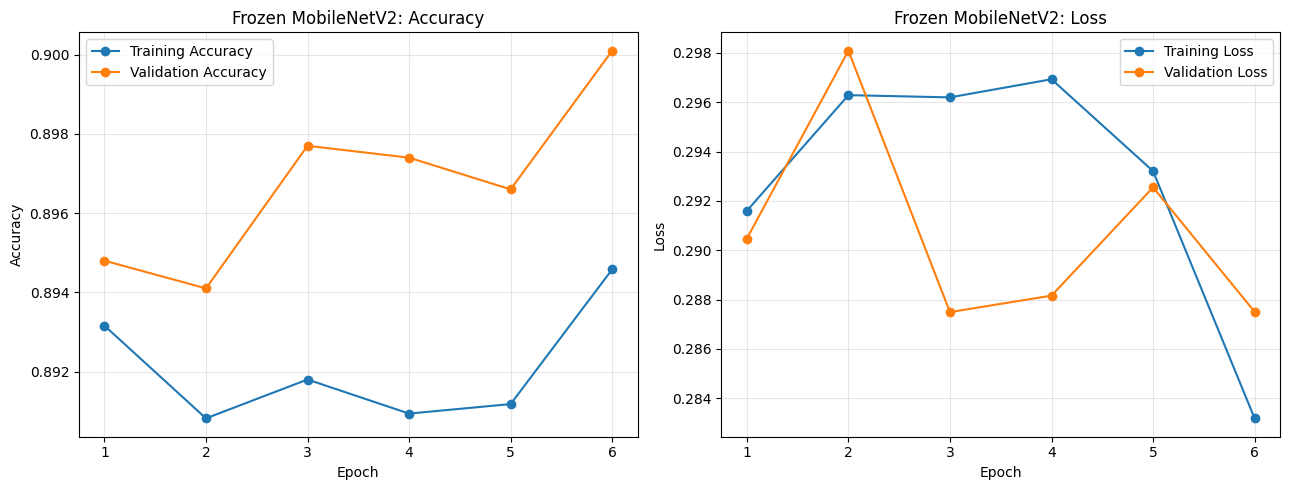


FROZEN MOBILENETV2 TEST RESULTS
Test loss: 0.2990
Test accuracy: 0.8923
Test accuracy: 89.23%
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step

Probability array shape: (10000, 10)
Predicted-label array shape: (10000,)

FROZEN MOBILENETV2 CLASSIFICATION REPORT
              precision    recall  f1-score   support

 T-shirt/top     0.8480    0.8480    0.8480      1000
     Trouser     0.9909    0.9770    0.9839      1000
    Pullover     0.8482    0.8380    0.8431      1000
       Dress     0.8663    0.8880    0.8770      1000
        Coat     0.8310    0.8160    0.8234      1000
      Sandal     0.9626    0.9780    0.9702      1000
       Shirt     0.6874    0.6970    0.6922      1000
     Sneaker     0.9550    0.9330    0.9439      1000
         Bag     0.9830    0.9850    0.9840      1000
  Ankle boot     0.9535    0.9630    0.9582      1000

    accuracy                         0.8923     10000
   macro avg     0.8926    0.8923    0.8924     10000
weighted avg     0.8926    0.8923    0.892

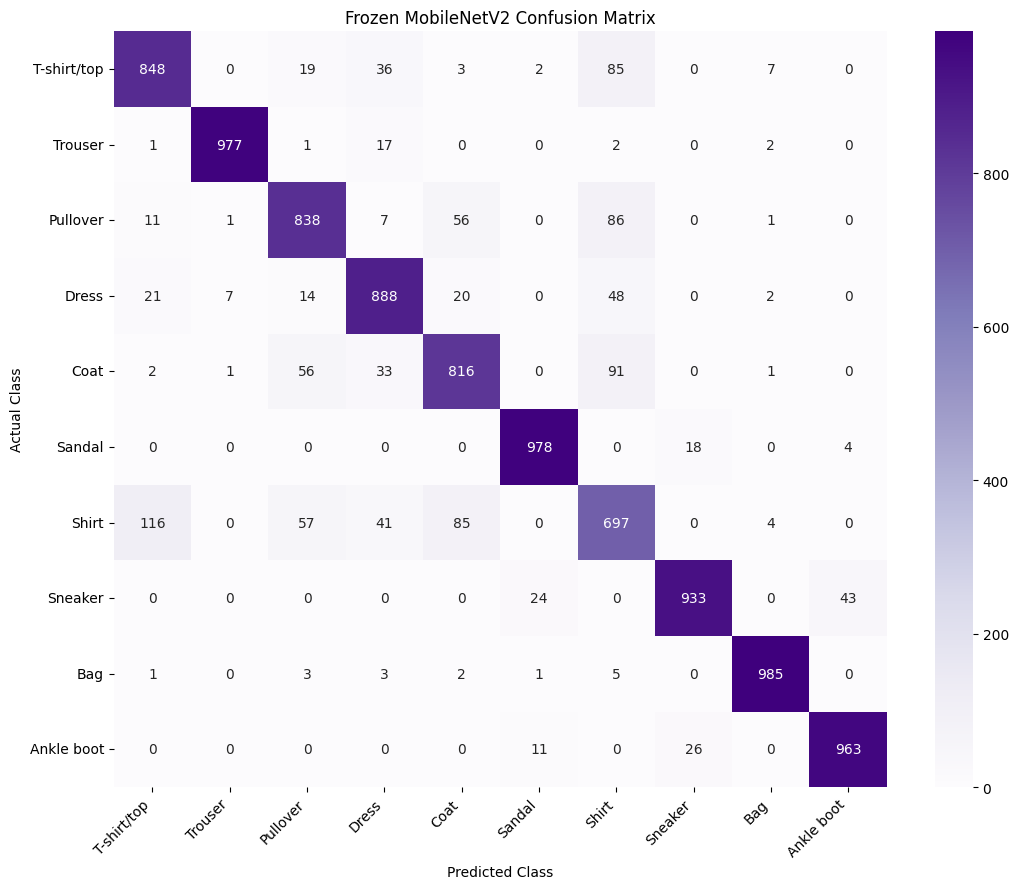

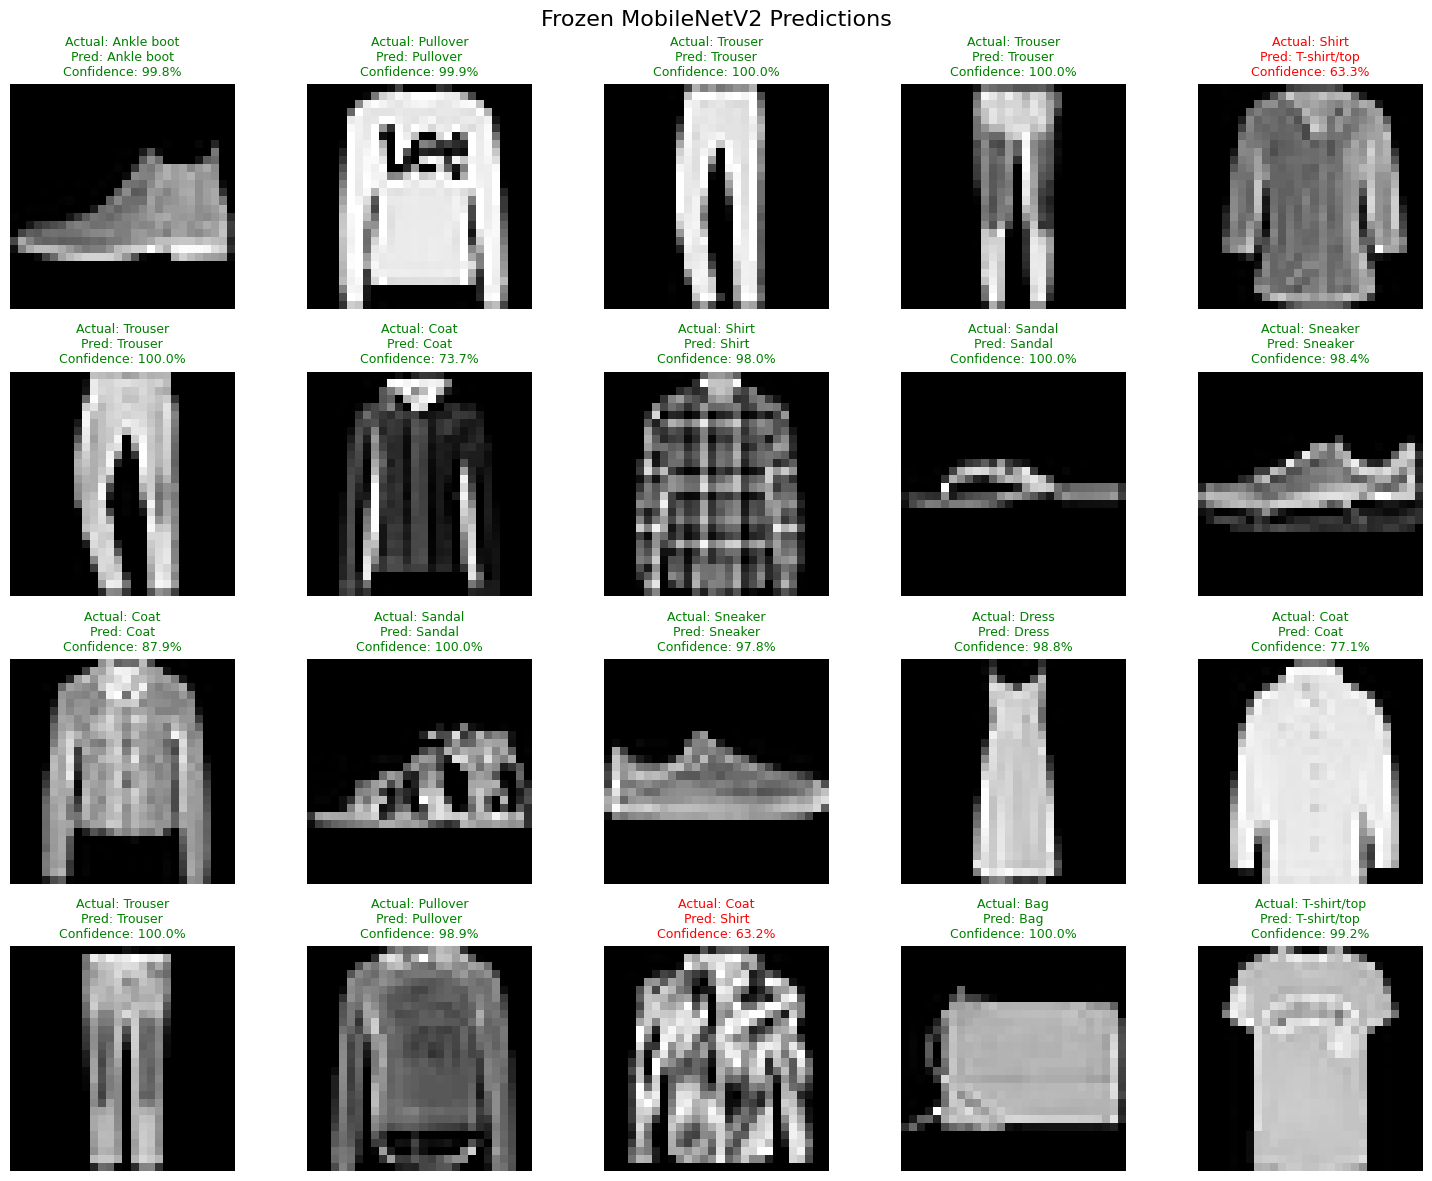


Saved result:
{'Model': 'MobileNetV2 Frozen', 'Test Loss': 0.2989840507507324, 'Test Accuracy': 0.892300009727478}


In [55]:
# ============================================================
# FROZEN MOBILENETV2: TRAINING, EVALUATION AND VISUALIZATION
# ============================================================

# 1. Compile the frozen MobileNet model
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 2. Create callbacks
mobilenet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# 3. Train the frozen MobileNet model
print("=" * 60)
print("TRAINING FROZEN MOBILENETV2")
print("=" * 60)

mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=mobilenet_callbacks,
    verbose=1
)

# 4. Plot training and validation curves
history_data = mobilenet_history.history
epochs_range = range(1, len(history_data["loss"]) + 1)

plt.figure(figsize=(13, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history_data["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history_data["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Frozen MobileNetV2: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history_data["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history_data["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Frozen MobileNetV2: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 5. Evaluate the model on the test dataset
mobilenet_frozen_loss, mobilenet_frozen_accuracy = (
    mobilenet_model.evaluate(
        test_dataset,
        verbose=0
    )
)

print("\n" + "=" * 60)
print("FROZEN MOBILENETV2 TEST RESULTS")
print("=" * 60)

print(f"Test loss: {mobilenet_frozen_loss:.4f}")
print(f"Test accuracy: {mobilenet_frozen_accuracy:.4f}")
print(f"Test accuracy: {mobilenet_frozen_accuracy * 100:.2f}%")

# 6. Generate probabilities and predicted classes
mobilenet_frozen_probabilities = mobilenet_model.predict(
    test_dataset,
    verbose=1
)

mobilenet_frozen_predictions = np.argmax(
    mobilenet_frozen_probabilities,
    axis=1
)

print(
    "\nProbability array shape:",
    mobilenet_frozen_probabilities.shape
)

print(
    "Predicted-label array shape:",
    mobilenet_frozen_predictions.shape
)

# 7. Classification report
print("\n" + "=" * 60)
print("FROZEN MOBILENETV2 CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        mobilenet_frozen_predictions,
        target_names=class_names,
        digits=4
    )
)

# 8. Confusion matrix
mobilenet_frozen_cm = confusion_matrix(
    y_test,
    mobilenet_frozen_predictions
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    mobilenet_frozen_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Frozen MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 9. Display sample predictions
plt.figure(figsize=(15, 12))

for i in range(20):
    predicted_class = mobilenet_frozen_predictions[i]
    actual_class = y_test[i]

    confidence = (
        mobilenet_frozen_probabilities[i][predicted_class] * 100
    )

    title_color = (
        "green"
        if predicted_class == actual_class
        else "red"
    )

    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")

    plt.title(
        f"Actual: {class_names[actual_class]}\n"
        f"Pred: {class_names[predicted_class]}\n"
        f"Confidence: {confidence:.1f}%",
        color=title_color,
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "Frozen MobileNetV2 Predictions",
    fontsize=16
)

plt.tight_layout()
plt.show()

# 10. Save the frozen MobileNet result
frozen_mobilenet_result = {
    "Model": "MobileNetV2 Frozen",
    "Test Loss": mobilenet_frozen_loss,
    "Test Accuracy": mobilenet_frozen_accuracy
}

print("\nSaved result:")
print(frozen_mobilenet_result)

Total MobileNet layers: 154
Fine-tuning starts at layer: 124
Trainable layers in MobileNet: 19

FINE-TUNING MOBILENETV2
Epoch 1/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 42s 65ms/step - accuracy: 0.9000 - loss: 0.2716 - val_accuracy: 0.9024 - val_loss: 0.2715 - learning_rate: 1.0000e-05
Epoch 2/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.9111 - loss: 0.2402 - val_accuracy: 0.9078 - val_loss: 0.2559 - learning_rate: 1.0000e-05
Epoch 3/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.9177 - loss: 0.2211 - val_accuracy: 0.9097 - val_loss: 0.2507 - learning_rate: 1.0000e-05
Epoch 4/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.9243 - loss: 0.2054 - val_accuracy: 0.9133 - val_loss: 0.2457 - learning_rate: 1.0000e-05
Epoch 5/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.9294 - loss: 0.1886 - val_accuracy: 0.9139 - val_loss: 0.2388 - learning_rate: 1.0000e-05
Epoch 6/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.9333 - loss: 0.1781 - 

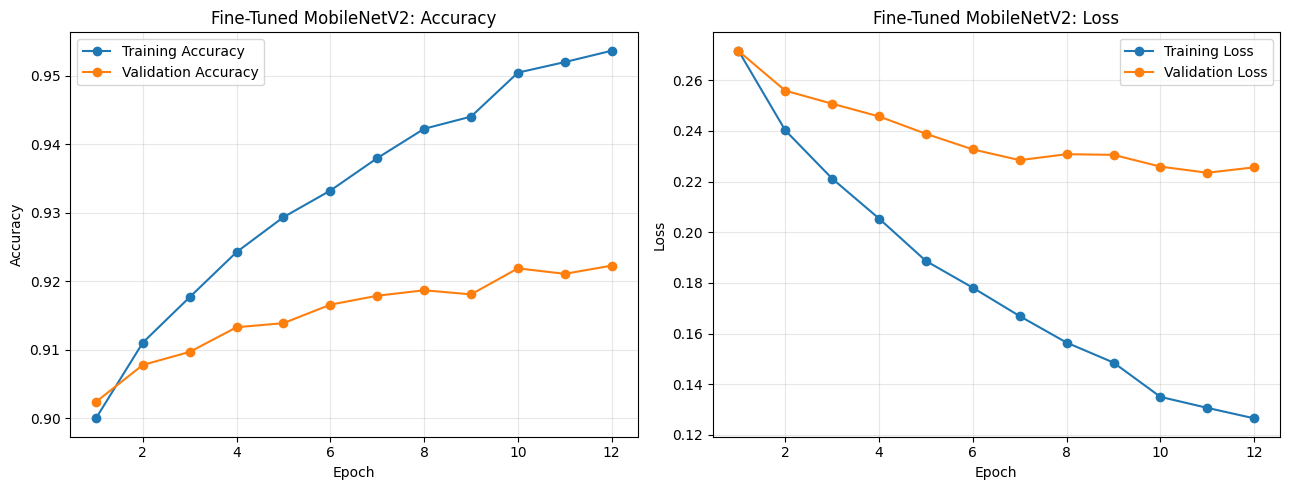


FINE-TUNED MOBILENETV2 TEST RESULTS
Test loss: 0.2365
Test accuracy: 0.9169
Test accuracy: 91.69%
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step

FINE-TUNED MOBILENETV2 CLASSIFICATION REPORT
              precision    recall  f1-score   support

 T-shirt/top     0.8723    0.8610    0.8666      1000
     Trouser     0.9959    0.9760    0.9859      1000
    Pullover     0.8840    0.8920    0.8880      1000
       Dress     0.9111    0.9120    0.9115      1000
        Coat     0.8570    0.8930    0.8746      1000
      Sandal     0.9744    0.9910    0.9826      1000
       Shirt     0.7587    0.7420    0.7503      1000
     Sneaker     0.9582    0.9620    0.9601      1000
         Bag     0.9870    0.9890    0.9880      1000
  Ankle boot     0.9704    0.9510    0.9606      1000

    accuracy                         0.9169     10000
   macro avg     0.9169    0.9169    0.9168     10000
weighted avg     0.9169    0.9169    0.9168     10000



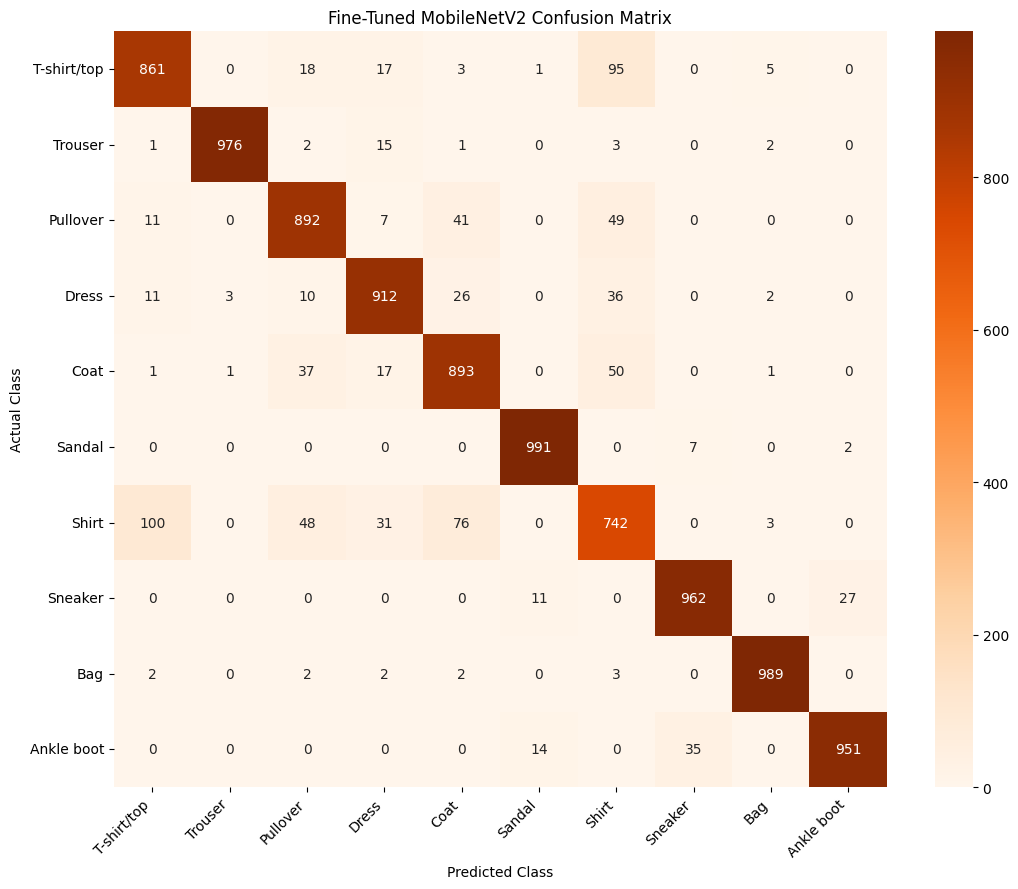

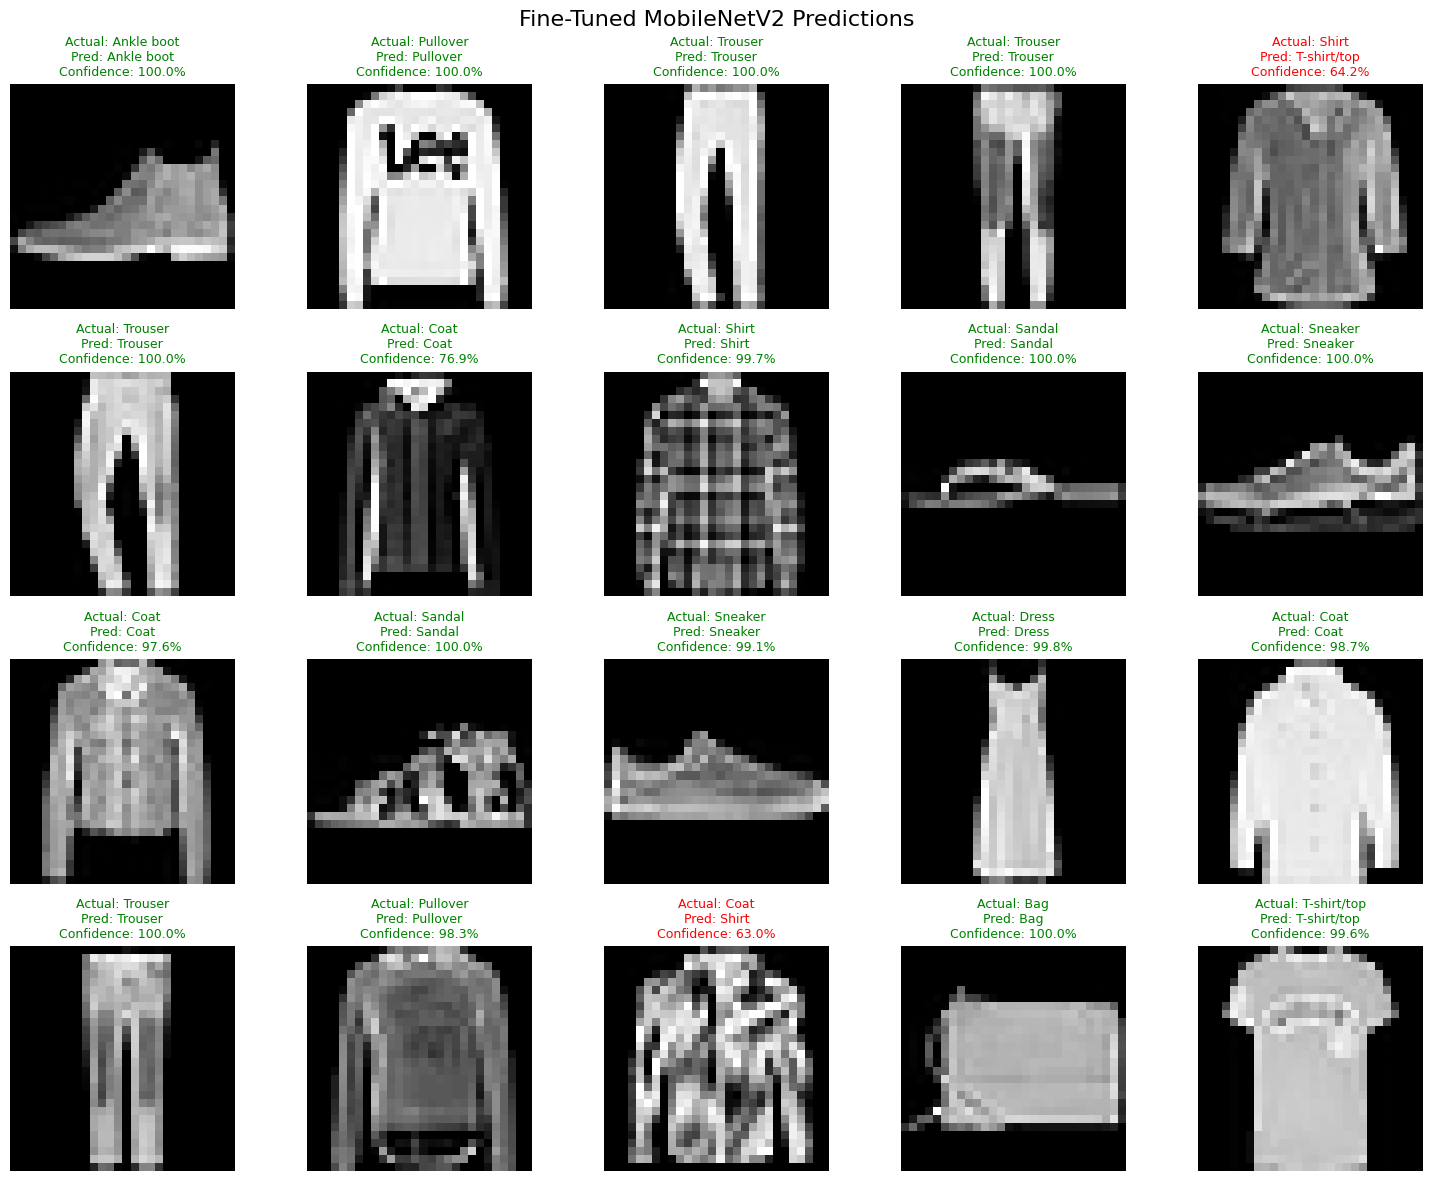


FINAL MODEL COMPARISON


,Model,Test Loss,Test Accuracy
0,Baseline Neural Network,0.3479,0.8766
1,Custom CNN,0.2173,0.9314
2,MobileNetV2 Frozen,0.2990,0.8923
3,MobileNetV2 Fine-Tuned,0.2365,0.9169


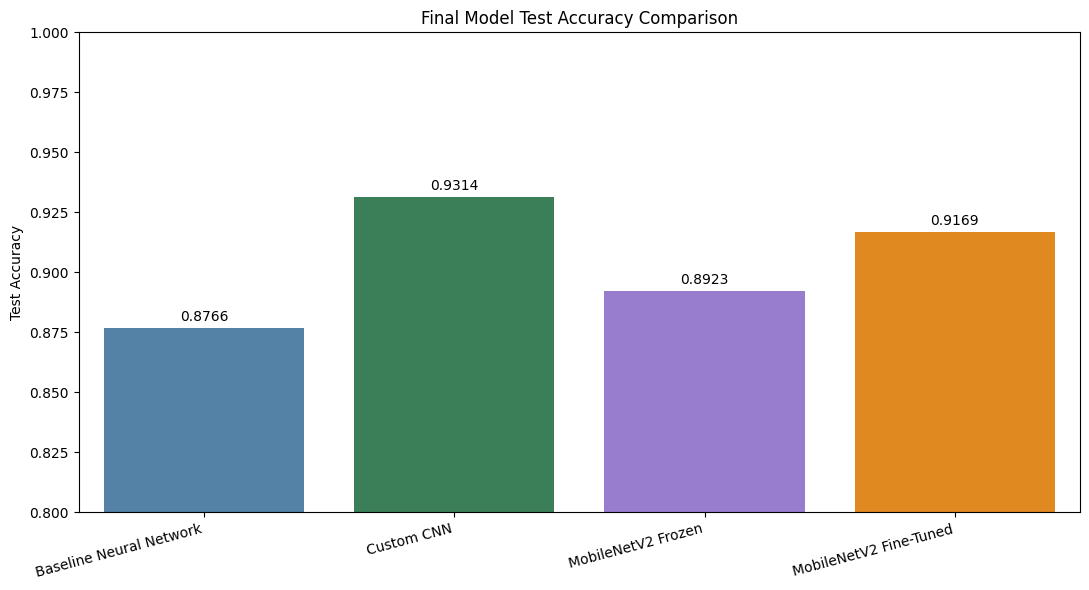


Best-performing model:
Model: Custom CNN
Test accuracy: 93.14%


In [56]:
# ============================================================
# MOBILENETV2 FINE-TUNING, EVALUATION AND MODEL COMPARISON
# ============================================================

# 1. Unfreeze the MobileNet base
mobilenet_base.trainable = True

# 2. Freeze all layers except the final 30 layers
fine_tune_from = len(mobilenet_base.layers) - 30

for layer in mobilenet_base.layers[:fine_tune_from]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in mobilenet_base.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total MobileNet layers:", len(mobilenet_base.layers))
print("Fine-tuning starts at layer:", fine_tune_from)

print(
    "Trainable layers in MobileNet:",
    sum(layer.trainable for layer in mobilenet_base.layers)
)

# 3. Recompile after changing trainable layers
# Use a very small learning rate to protect pretrained weights
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Fine-tuning callbacks
fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# 5. Fine-tune the model
print("\n" + "=" * 60)
print("FINE-TUNING MOBILENETV2")
print("=" * 60)

fine_tune_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=12,
    callbacks=fine_tune_callbacks,
    verbose=1
)

# 6. Plot fine-tuning curves
fine_history = fine_tune_history.history
fine_epochs = range(1, len(fine_history["loss"]) + 1)

plt.figure(figsize=(13, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    fine_epochs,
    fine_history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    fine_epochs,
    fine_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Fine-Tuned MobileNetV2: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    fine_epochs,
    fine_history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    fine_epochs,
    fine_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Fine-Tuned MobileNetV2: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 7. Evaluate the fine-tuned model
mobilenet_finetuned_loss, mobilenet_finetuned_accuracy = (
    mobilenet_model.evaluate(
        test_dataset,
        verbose=0
    )
)

print("\n" + "=" * 60)
print("FINE-TUNED MOBILENETV2 TEST RESULTS")
print("=" * 60)

print(f"Test loss: {mobilenet_finetuned_loss:.4f}")
print(f"Test accuracy: {mobilenet_finetuned_accuracy:.4f}")
print(
    f"Test accuracy: "
    f"{mobilenet_finetuned_accuracy * 100:.2f}%"
)

# 8. Generate fine-tuned predictions
mobilenet_finetuned_probabilities = mobilenet_model.predict(
    test_dataset,
    verbose=1
)

mobilenet_finetuned_predictions = np.argmax(
    mobilenet_finetuned_probabilities,
    axis=1
)

# 9. Classification report
print("\n" + "=" * 60)
print("FINE-TUNED MOBILENETV2 CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        mobilenet_finetuned_predictions,
        target_names=class_names,
        digits=4
    )
)

# 10. Confusion matrix
mobilenet_finetuned_cm = confusion_matrix(
    y_test,
    mobilenet_finetuned_predictions
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    mobilenet_finetuned_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fine-Tuned MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 11. Show sample predictions
plt.figure(figsize=(15, 12))

for i in range(20):
    predicted_class = mobilenet_finetuned_predictions[i]
    actual_class = y_test[i]

    confidence = (
        mobilenet_finetuned_probabilities[i][predicted_class]
        * 100
    )

    title_color = (
        "green"
        if predicted_class == actual_class
        else "red"
    )

    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")

    plt.title(
        f"Actual: {class_names[actual_class]}\n"
        f"Pred: {class_names[predicted_class]}\n"
        f"Confidence: {confidence:.1f}%",
        color=title_color,
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "Fine-Tuned MobileNetV2 Predictions",
    fontsize=16
)

plt.tight_layout()
plt.show()

# 12. Create final comparison table
final_results_df = pd.DataFrame([
    {
        "Model": "Baseline Neural Network",
        "Test Loss": baseline_test_loss,
        "Test Accuracy": baseline_test_accuracy
    },
    {
        "Model": "Custom CNN",
        "Test Loss": cnn_test_loss,
        "Test Accuracy": cnn_test_accuracy
    },
    {
        "Model": "MobileNetV2 Frozen",
        "Test Loss": mobilenet_frozen_loss,
        "Test Accuracy": mobilenet_frozen_accuracy
    },
    {
        "Model": "MobileNetV2 Fine-Tuned",
        "Test Loss": mobilenet_finetuned_loss,
        "Test Accuracy": mobilenet_finetuned_accuracy
    }
])

print("\n" + "=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

display(
    final_results_df.style.format({
        "Test Loss": "{:.4f}",
        "Test Accuracy": "{:.4f}"
    })
)

# 13. Plot final accuracy comparison
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=final_results_df,
    x="Model",
    y="Test Accuracy",
    hue="Model",
    palette=[
        "steelblue",
        "seagreen",
        "mediumpurple",
        "darkorange"
    ],
    legend=False
)

plt.title("Final Model Test Accuracy Comparison")
plt.xlabel("")
plt.ylabel("Test Accuracy")
plt.ylim(0.80, 1.00)
plt.xticks(rotation=15, ha="right")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()
plt.show()

# 14. Identify the best model
best_index = final_results_df["Test Accuracy"].idxmax()
best_model_result = final_results_df.loc[best_index]

print("\nBest-performing model:")
print("Model:", best_model_result["Model"])
print(
    f"Test accuracy: "
    f"{best_model_result['Test Accuracy'] * 100:.2f}%"
)

## Final Model Comparison and Conclusion

The custom CNN was the best-performing model, achieving a test accuracy
of 93.14%. It outperformed the baseline neural network, which achieved
87.66%, and both MobileNetV2 transfer-learning configurations.

The CNN improved upon the baseline because its convolutional layers
preserved spatial relationships and learned relevant visual features
such as edges, shapes and clothing patterns.

Although MobileNetV2 used features pretrained on ImageNet, it did not
outperform the custom CNN. Fashion-MNIST consists of small 28 × 28
grayscale clothing silhouettes, while ImageNet contains larger RGB
photographs of complex real-world objects. This domain difference
limited the usefulness of MobileNetV2's pretrained features.

Therefore, transfer learning is not automatically superior for every
image-classification problem. A smaller model designed specifically for
the target dataset may achieve better performance while also requiring
less computation.

In [57]:
# Save the best-performing CNN model
best_model_path = "fashion_mnist_cnn_best.keras"

cnn_model.save(best_model_path)

print("Best model saved successfully.")
print("Model:", "Custom CNN")
print(f"Test accuracy: {cnn_test_accuracy * 100:.2f}%")
print("Saved file:", best_model_path)

Best model saved successfully.
Model: Custom CNN
Test accuracy: 93.14%
Saved file: fashion_mnist_cnn_best.keras


In [58]:
# Load the saved model
loaded_cnn_model = keras.models.load_model(
    "fashion_mnist_cnn_best.keras"
)

# Evaluate it again
loaded_loss, loaded_accuracy = loaded_cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print(f"Loaded model test loss: {loaded_loss:.4f}")
print(f"Loaded model test accuracy: {loaded_accuracy * 100:.2f}%")

Loaded model test loss: 0.2173
Loaded model test accuracy: 93.14%


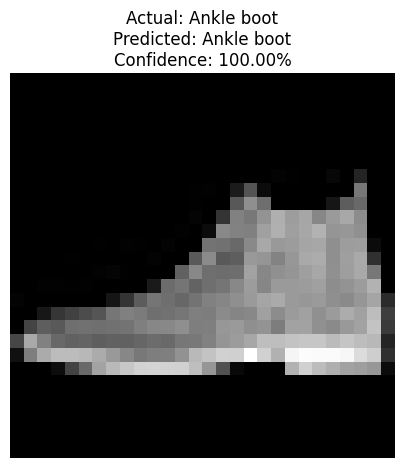

Actual class: Ankle boot
Predicted class: Ankle boot
Confidence: 100.00%


In [59]:
# Select one test image
image_index = 0
sample_image = X_test_cnn[image_index]

# Add a batch dimension: (28, 28, 1) → (1, 28, 28, 1)
input_image = np.expand_dims(sample_image, axis=0)

# Predict probabilities
prediction_probabilities = loaded_cnn_model.predict(
    input_image,
    verbose=0
)[0]

predicted_class = np.argmax(prediction_probabilities)
actual_class = y_test[image_index]
confidence = prediction_probabilities[predicted_class] * 100

# Display the result
plt.figure(figsize=(5, 5))
plt.imshow(X_test[image_index], cmap="gray")

plt.title(
    f"Actual: {class_names[actual_class]}\n"
    f"Predicted: {class_names[predicted_class]}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

print("Actual class:", class_names[actual_class])
print("Predicted class:", class_names[predicted_class])
print(f"Confidence: {confidence:.2f}%")

In [60]:
from google.colab import files

files.download("fashion_mnist_cnn_best.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>